# Thesis Workspace
This Jupyter notebook was used to create necessary scripts for supporting UMEP in an interactive way, thus it is not organized in a straight forward way, with various additions occuring at different stages along the process of writing the original thesis.

In [1]:
import subprocess
import sys
import os

def install(package):
    subprocess.check_call([sys.executable, "-m", "pip", "install", package])

In [211]:
def upgrade(package):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade", package])

In [2]:
import geopandas as gpd
import geopy as gpy
from geopy import distance
from osgeo import gdal
from osgeo import osr
import numpy as np
import pandas as pd
import osmnx as ox
import matplotlib.pyplot as plt
# import rasterio as rast
# import rasterio.features as ft

In [24]:
install("shapely")

In [25]:
import pygeoprocessing as pygeo
import shapely

In [26]:
import random
import math

### Momepy Definitions needed for creating visualizations

In [27]:
def _make_circle(points):
    # Convert to float and randomize order
    shuffled = [(float(x), float(y)) for (x, y) in points]
    random.shuffle(shuffled)

    # Progressively add points to circle or recompute circle
    c = None
    for (i, p) in enumerate(shuffled):
        if c is None or not _is_in_circle(c, p):
            c = _make_circle_one_point(shuffled[: i + 1], p)
    return c


# One boundary point known
def _make_circle_one_point(points, p):
    c = (p[0], p[1], 0.0)
    for (i, q) in enumerate(points):
        if not _is_in_circle(c, q):
            if c[2] == 0.0:
                c = _make_diameter(p, q)
            else:
                c = _make_circle_two_points(points[: i + 1], p, q)
    return c


# Two boundary points known
def _make_circle_two_points(points, p, q):
    circ = _make_diameter(p, q)
    left = None
    right = None
    px, py = p
    qx, qy = q

    # For each point not in the two-point circle
    for r in points:
        if _is_in_circle(circ, r):
            continue

        # Form a circumcircle and classify it on left or right side
        cross = _cross_product(px, py, qx, qy, r[0], r[1])
        c = _make_circumcircle(p, q, r)
        if c is None:
            continue
        elif cross > 0.0 and (
            left is None
            or _cross_product(px, py, qx, qy, c[0], c[1])
            > _cross_product(px, py, qx, qy, left[0], left[1])
        ):
            left = c
        elif cross < 0.0 and (
            right is None
            or _cross_product(px, py, qx, qy, c[0], c[1])
            < _cross_product(px, py, qx, qy, right[0], right[1])
        ):
            right = c

    # Select which circle to return
    if left is None and right is None:
        return circ
    if left is None:
        return right
    if right is None:
        return left
    if left[2] <= right[2]:
        return left
    return right


def _make_circumcircle(p0, p1, p2):
    # Mathematical algorithm from Wikipedia: Circumscribed circle
    ax, ay = p0
    bx, by = p1
    cx, cy = p2
    ox = (min(ax, bx, cx) + max(ax, bx, cx)) / 2.0
    oy = (min(ay, by, cy) + max(ay, by, cy)) / 2.0
    ax -= ox
    ay -= oy
    bx -= ox
    by -= oy
    cx -= ox
    cy -= oy
    d = (ax * (by - cy) + bx * (cy - ay) + cx * (ay - by)) * 2.0
    if d == 0.0:
        return None
    x = (
        ox
        + (
            (ax * ax + ay * ay) * (by - cy)
            + (bx * bx + by * by) * (cy - ay)
            + (cx * cx + cy * cy) * (ay - by)
        )
        / d
    )
    y = (
        oy
        + (
            (ax * ax + ay * ay) * (cx - bx)
            + (bx * bx + by * by) * (ax - cx)
            + (cx * cx + cy * cy) * (bx - ax)
        )
        / d
    )
    ra = math.hypot(x - p0[0], y - p0[1])
    rb = math.hypot(x - p1[0], y - p1[1])
    rc = math.hypot(x - p2[0], y - p2[1])
    return (x, y, max(ra, rb, rc))


def _make_diameter(p0, p1):
    cx = (p0[0] + p1[0]) / 2.0
    cy = (p0[1] + p1[1]) / 2.0
    r0 = math.hypot(cx - p0[0], cy - p0[1])
    r1 = math.hypot(cx - p1[0], cy - p1[1])
    return (cx, cy, max(r0, r1))


_MULTIPLICATIVE_EPSILON = 1 + 1e-14


def _is_in_circle(c, p):
    return (
        c is not None
        and math.hypot(p[0] - c[0], p[1] - c[1]) <= c[2] * _MULTIPLICATIVE_EPSILON
    )


# Returns twice the signed area of the triangle defined by (x0, y0), (x1, y1), (x2, y2).
def _cross_product(x0, y0, x1, y1, x2, y2):
    return (x1 - x0) * (y2 - y0) - (y1 - y0) * (x2 - x0)


# end of Nayuiki script to define the smallest enclosing circle


# calculate the area of circumcircle
def _circle_area(points):
    if len(points[0]) == 3:
        points = [x[:2] for x in points]
    circ = _make_circle(points)
    return math.pi * circ[2] ** 2

def _circle_radius(points):
    if len(points[0]) == 3:
        points = [x[:2] for x in points]
    circ = _make_circle(points)
    return circ[2]


def _true_angle(a, b, c):
    # calculate angle between points, return true or false if real corner
    ba = a - b
    bc = c - b

    cosine_angle = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc))
    angle = np.arccos(cosine_angle)

    if np.degrees(angle) <= 170:
        return True
    if np.degrees(angle) >= 190:
        return True
    return False


def get_corners(geom):
#    count corners of geom
    if geom is None:
        return None
    corners = 0  # define empty variables
    points = list(geom.exterior.coords)  # get points of a shape
    stop = len(points) - 1  # define where to stop
    for i in np.arange(
        len(points)
    ):  # for every point, calculate angle and add 1 if True angle
        if i == 0:
            continue
        elif i == stop:
            a = np.asarray(points[i - 1])
            b = np.asarray(points[i])
            c = np.asarray(points[1])

            if _true_angle(a, b, c) is True:
                corners = corners + 1
            else:
                continue

        else:
            a = np.asarray(points[i - 1])
            b = np.asarray(points[i])
            c = np.asarray(points[i + 1])

            if _true_angle(a, b, c) is True:
                corners = corners + 1
            else:
                continue
    
    return corners

def squareness(geom):
    if geom is None:
        return None
    
    def _angle(a, b, c):
        ba = a - b
        bc = c - b

        cosine_angle = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc))
        angle = np.degrees(np.arccos(cosine_angle))

        return angle
    
    angles = []
    points = list(geom.exterior.coords)  # get points of a shape
    stop = len(points) - 1  # define where to stop
    for i in np.arange(
        len(points)
    ):  # for every point, calculate angle and add 1 if True angle
        if i == 0:
            continue
        elif i == stop:
            a = np.asarray(points[i - 1])
            b = np.asarray(points[i])
            c = np.asarray(points[1])
            ang = _angle(a, b, c)

            if ang <= 175:
                angles.append(ang)
            elif _angle(a, b, c) >= 185:
                angles.append(ang)
            else:
                continue

        else:
            a = np.asarray(points[i - 1])
            b = np.asarray(points[i])
            c = np.asarray(points[i + 1])
            ang = _angle(a, b, c)

            if _angle(a, b, c) <= 175:
                angles.append(ang)
            elif _angle(a, b, c) >= 185:
                angles.append(ang)
            else:
                continue
    deviations = [abs(90 - i) for i in angles]
    return np.mean(deviations)


def elongation(bbox):
    a = bbox.area
    p = bbox.length
    cond1 = p ** 2
    cond2 = 16 * a
    bigger = cond1 >= cond2
    sqrt = np.empty(len(a))
    sqrt[bigger] = cond1[bigger] - cond2[bigger]
    sqrt[~bigger] = 0

    elo1 = ((p - np.sqrt(sqrt)) / 4) / ((p / 2) - ((p - np.sqrt(sqrt)) / 4))
    elo2 = ((p + np.sqrt(sqrt)) / 4) / ((p / 2) - ((p + np.sqrt(sqrt)) / 4))

    # use the smaller one (e.g. shorter/longer)
    res = np.empty(len(a))
    res[elo1 <= elo2] = elo1[elo1 <= elo2]
    res[~(elo1 <= elo2)] = elo2[~(elo1 <= elo2)]
    return res


def centroid_corner(geom):
    '''all these characters working with corners could be merged and cleaned
    '''
    from shapely.geometry import Point
    
    if geom is None:
        return (None, None)
    
    distances = []  # set empty list of distances
    centroid = geom.centroid  # define centroid
    points = list(geom.exterior.coords)  # get points of a shape
    stop = len(points) - 1  # define where to stop
    for i in np.arange(
        len(points)
    ):  # for every point, calculate angle and add 1 if True angle
        if i == 0:
            continue
        elif i == stop:
            a = np.asarray(points[i - 1])
            b = np.asarray(points[i])
            c = np.asarray(points[1])
            p = Point(points[i])

            if _true_angle(a, b, c) is True:
                distance = centroid.distance(
                    p
                )  # calculate distance point - centroid
                distances.append(distance)  # add distance to the list
            else:
                continue

        else:
            a = np.asarray(points[i - 1])
            b = np.asarray(points[i])
            c = np.asarray(points[i + 1])
            p = Point(points[i])

            if _true_angle(a, b, c) is True:
                distance = centroid.distance(p)
                distances.append(distance)
            else:
                continue
    if not distances:  # circular buildings
        from momepy.dimension import _circle_radius

        if geom.has_z:
            coords = [
                (coo[0], coo[1]) for coo in geom.convex_hull.exterior.coords
            ]
        else:
            coords = geom.convex_hull.exterior.coords
        return (_circle_radius(coords), 0)

    return (np.mean(distances), np.std(distances))


def _azimuth(point1, point2):
    """azimuth between 2 shapely points (interval 0 - 180)"""
    angle = np.arctan2(point2[0] - point1[0], point2[1] - point1[1])
    return np.degrees(angle) if angle > 0 else np.degrees(angle) + 180


def _dist(a, b):
    return math.hypot(b[0] - a[0], b[1] - a[1])


def solar_orientation_poly(bbox):
    if bbox is None:
        return None
    bbox = list(bbox.exterior.coords)
    axis1 = _dist(bbox[0], bbox[3])
    axis2 = _dist(bbox[0], bbox[1])

    if axis1 <= axis2:
        az = _azimuth(bbox[0], bbox[1])
    else:
        az = _azimuth(bbox[0], bbox[3])
    
    if 90 > az >= 45:
        diff = az - 45
        az = az - 2 * diff
    elif 135 > az >= 90:
        diff = az - 90
        az = az - 2 * diff
        diff = az - 45
        az = az - 2 * diff
    elif 181 > az >= 135:
        diff = az - 135
        az = az - 2 * diff
        diff = az - 90
        az = az - 2 * diff
        diff = az - 45
        az = az - 2 * diff
        
    return az


def street_profile(streets, buildings, distance=3, tick_length=50):

    pygeos_lines = streets.geometry.values.data

    list_points = np.empty((0, 2))
    ids = []

    lengths = shapely.length(pygeos_lines)
    for ix, (line, length) in enumerate(zip(pygeos_lines, lengths)):

        pts = shapely.line_interpolate_point(
            line, np.linspace(0, length, num=int((length) // distance))
        )  # .1 offset to keep a gap between two segments
        list_points = np.append(list_points, shapely.get_coordinates(pts), axis=0)
        ids += [ix] * len(pts) * 2


    ticks = []
    for num, pt in enumerate(list_points, 1):
        # start chainage 0
        if num == 1:
            angle = _getAngle(pt, list_points[num])
            line_end_1 = _getPoint1(pt, angle, tick_length / 2)
            angle = _getAngle(line_end_1, pt)
            line_end_2 = _getPoint2(line_end_1, angle, tick_length)
            ticks.append([line_end_1, pt])
            ticks.append([line_end_2, pt])

        # everything in between
        if num < len(list_points) - 1:
            angle = _getAngle(pt, list_points[num])
            line_end_1 = _getPoint1(
                list_points[num], angle, tick_length / 2
            )
            angle = _getAngle(line_end_1, list_points[num])
            line_end_2 = _getPoint2(line_end_1, angle, tick_length)
            ticks.append([line_end_1, list_points[num]])
            ticks.append([line_end_2, list_points[num]])

        # end chainage
        if num == len(list_points):
            angle = _getAngle(list_points[num - 2], pt)
            line_end_1 = _getPoint1(pt, angle, tick_length / 2)
            angle = _getAngle(line_end_1, pt)
            line_end_2 = _getPoint2(line_end_1, angle, tick_length)
            ticks.append([line_end_1, pt])
            ticks.append([line_end_2, pt])

    ticks = shapely.linestrings(ticks)
    inp, res = shapely.STRtree(ticks).query(buildings.geometry.values.data, predicate='intersects')
    intersections = shapely.intersection(ticks[res], buildings.geometry.values.data[inp])
    distances = shapely.distance(intersections, shapely.points(list_points[res // 2]))

    dists = np.zeros((len(ticks),))
    dists[:] = np.nan
    dists[res] = distances

    ids = np.array(ids)
    widths = []
    openness = []
    deviations = []
    for i in range(len(streets)):
        f = ids == i
        s = dists[f]
        lefts = s[::2]
        rights = s[1::2]
        left_mean = np.nanmean(lefts) if ~np.isnan(lefts).all() else tick_length / 2
        right_mean = np.nanmean(rights) if ~np.isnan(rights).all() else tick_length / 2
        widths.append(np.mean([left_mean, right_mean]) * 2)
        openness.append(np.isnan(s).sum() / (f).sum())
        deviations.append(np.nanstd(s))
    
    return (widths, deviations, openness)


# http://wikicode.wikidot.com/get-angle-of-line-between-two-points
# https://glenbambrick.com/tag/perpendicular/
# angle between two points
def _getAngle(pt1, pt2):
    """
    pt1, pt2 : tuple
    """
    x_diff = pt2[0] - pt1[0]
    y_diff = pt2[1] - pt1[1]
    return math.degrees(math.atan2(y_diff, x_diff))

# start and end points of chainage tick
# get the first end point of a tick
def _getPoint1(pt, bearing, dist):
    """
    pt : tuple
    """
    angle = bearing + 90
    bearing = math.radians(angle)
    x = pt[0] + dist * math.cos(bearing)
    y = pt[1] + dist * math.sin(bearing)
    return (x, y)

# get the second end point of a tick
def _getPoint2(pt, bearing, dist):
    """
    pt : tuple
    """
    bearing = math.radians(bearing)
    x = pt[0] + dist * math.cos(bearing)
    y = pt[1] + dist * math.sin(bearing)
    return (x, y)


def get_edge_ratios(df, edges):
    """
    df: cells/buildngs
    edges: network
    """
    
    # intersection-based join
    buff = edges.buffer(0.01)  # to avoid floating point error
    inp, res = buff.sindex.query(df.geometry, predicate='intersects')
    intersections = df.iloc[inp].reset_index(drop=True).intersection(buff.iloc[res].reset_index(drop=True))
    mask = intersections.area > 0.0001
    intersections = intersections[mask]
    inp = inp[mask]
    lengths = intersections.area
    grouped = lengths.groupby(inp)
    totals = grouped.sum()
    ints_vect = []
    for name, group in grouped:
        ratios = group / totals.loc[name]
        ints_vect.append({res[item[0]]: item[1] for item in ratios.items()})
    
    edge_dicts = pd.Series(ints_vect, index=totals.index)
    
    # nearest neighbor join
    nans = df.index[~df.index.isin(edge_dicts.index)]
    buffered = df.loc[nans].buffer(500)
    additional = []
    for i in range(len(buffered)):
        geom = buffered.geometry.iloc[i]
        query = edges.sindex.query(geom)
        b = 500
        while query.size == 0:
            query = edges.sindex.query(geom.buffer(b))
            b += 500
        additional.append({edges.iloc[query].distance(geom).idxmin(): 1})

    additional = pd.Series(additional, index=nans)
    return pd.concat([edge_dicts, additional]).sort_index()


def get_nodes(df, nodes, edges, node_id, edge_id, startID, endID):
    nodes = nodes.set_index('nodeID')
    
    node_ids = []

    for edge_dict, geom in zip(df[edge_id], df.geometry):
        edge = edges.iloc[max(edge_dict, key=edge_dict.get)]
        startID = edge.node_start
        start = nodes.loc[startID].geometry
        sd = geom.distance(start)
        endID = edge.node_end
        end = nodes.loc[endID].geometry
        ed = geom.distance(end)
        if sd > ed:
            node_ids.append(endID)
        else:
            node_ids.append(startID)
    
    return pd.Series(node_ids, index=df.index)


### Extent and Tree Defs

In [13]:
EXTENT_PATH = "C://Users//alek-//Documents//Wageningen Thesis//Study_Area_data//StudyAreaExtent_v2.shp"
extentSHP = gpd.read_file(EXTENT_PATH)

In [5]:
extentSHP

,id,geometry
0,1,"POLYGON ((-118.25228 34.04995, -118.2204 34.04..."


In [4]:
OUT_PATH = "C://Users//alek-//Documents//Wageningen Thesis//Study_Area_data//"

In [5]:
TREE_GEN_FINAL_FILE_PATH = "C://Users//alek-//Documents//Wageningen Thesis//Study_Area_data//treePolyReprojv2.gpkg"
treeFinalPolyFile = gpd.read_file(TREE_GEN_FINAL_FILE_PATH)

In [15]:
avgTreeD = 45/np.pi
avgTreeD

14.32394487827058

In [8]:
treeFinalPolyFile.mean(numeric_only=True)

Confidence    25.715876
Shape_Leng    18.722462
Shape_Area    22.995786
Confiden_1    25.998699
Shape_Le_1    18.354864
Shape_Ar_1    21.939467
diameter       5.471918
trunk          2.801321
ttype          3.506539
totheight      4.672293
trType         1.830303
dtype: float64

In [10]:
treeFinalPolyFile.std(numeric_only=True, ddof=0)

Confidence    10.265741
Shape_Leng     8.497637
Shape_Area    22.513277
Confiden_1    10.657604
Shape_Le_1     7.863618
Shape_Ar_1    20.894921
diameter       2.440583
trunk          1.455327
ttype          0.499957
totheight      1.907683
trType         0.375366
dtype: float64

### Visualizations for Test Report

In [89]:
install('pyarrow')
import pyarrow

In [ ]:
TESS_FILE_PATH_REPORT = "C://Users//alek-//Documents//Wageningen Thesis//ReportData//tessellation_spatialSigAnalysis.shp"
tessForRep = gpd.read_file(TESS_FILE_PATH_REPORT)
 # Use 1935 or 1943


In [159]:
BUILDING_FILE_PATH_REPORT = "C://Users//alek-//Documents//Wageningen Thesis//software_exploration//data_for_spatial_sig//output//finalClusterForComparisons.pq"
buildingForRep = gpd.read_parquet(BUILDING_FILE_PATH_REPORT)


#### Circular compactness visualizations

In [ ]:
tess1935 = tessForRep.loc[tessForRep.tID == 1935]
tess1228 = tessForRep.loc[tessForRep.tID == 1228]


In [93]:
convTess1935 = tess1935.convex_hull
convTess1228 = tess1228.convex_hull

In [94]:
tessForDisp = pd.concat([tess1935, tess1228])

In [95]:
tessConv = tessForDisp.copy()
tessConv["geometry"] = tessConv.convex_hull

In [103]:
tessForDisp.to_parquet("C://Users//alek-//Documents//Wageningen Thesis//ReportData//TessForDisp2.pq")

In [96]:
tessConv.to_parquet("C://Users//alek-//Documents//Wageningen Thesis//ReportData//ConvHullForDisp2.pq")

In [97]:
coords = convTess1935.get_coordinates()
coord1935 = coords.values.tolist()
coords = convTess1228.get_coordinates()
coord1228 = coords.values.tolist()


In [98]:
circ1935 = _make_circle(coord1935)
circ1228 = _make_circle(coord1228)

In [99]:
circ_df = pd.DataFrame(
    {
        "tID": [1935, 1228],
        "cx": [circ1935[0], circ1228[0]],
        "cy": [circ1935[1], circ1228[1]],
        "radius": [circ1935[2], circ1228[2]]
    }
)

In [100]:
circ_gdf = gpd.GeoDataFrame(data=circ_df,geometry=gpd.points_from_xy(circ_df.cx,circ_df.cy), crs=convTess1935.crs)


In [101]:
circTrue_gdf = circ_gdf.copy()
circTrue_gdf["geometry"] = circTrue_gdf["geometry"].buffer(circTrue_gdf.radius)

In [102]:
circTrue_gdf.to_parquet("C://Users//alek-//Documents//Wageningen Thesis//ReportData//circForCCODisp2.pq")

#### Contiguity based visualizations

In [168]:
building1935 = buildingForRep[["buildings"]].loc[buildingForRep.index == 1935]
building1933 = buildingForRep[["buildings"]].loc[buildingForRep.index == 1933]
building1934 = buildingForRep[["buildings"]].loc[buildingForRep.index == 1934]
building1936 = buildingForRep[["buildings"]].loc[buildingForRep.index == 1936]
building1943 = buildingForRep[["buildings"]].loc[buildingForRep.index == 1943]
building1945 = buildingForRep[["buildings"]].loc[buildingForRep.index == 1945]
building1959 = buildingForRep[["buildings"]].loc[buildingForRep.index == 1959]

buildContigQueen1935 = pd.concat([building1935, building1933, building1934, building1936, 
                                 building1943, building1945, building1959])

In [171]:
buildContigQueen1935Env = buildContigQueen1935.copy()
buildContigQueen1935Env["geometry"] = buildContigQueen1935Env["buildings"].minimum_rotated_rectangle()

In [ ]:
buildContigQueen1935Env.drop(inplace=True, columns=["buildings"])
buildContigQueen1935Env.set_geometry("geometry", inplace=True)

In [132]:
i = 1
for bbox in env1935Contig:
    bbox = list(bbox.exterior.coords)
    axis1 = _dist(bbox[0], bbox[3])
    axis2 = _dist(bbox[0], bbox[1])
    print(i)
    print(axis1)
    print(_azimuth(bbox[0], bbox[3]))
    print(axis2)
    print(_azimuth(bbox[0], bbox[1]))
    i += 1

1
84.41033490246164
81.79810693944796
98.46778133866259
171.79810694007088
2
84.12901996843524
171.8069704590975
73.99532614646192
81.80697045879043
3
129.22676691559298
82.01366343478554
161.70587721340996
172.0136634349806
4
42.80510902922541
171.8835847826553
87.57723872179947
81.88358478304127
5
86.28646147486603
94.96525434829712
88.74612510167995
4.9652543487218
6
107.2920023188264
171.82911893167403
84.37706685187136
81.8291189316777
7
85.55850060487144
171.84943518220442
137.86550864332582
81.84943518202569


In [178]:
azBuildContig = []

for buildEnv in buildContigQueen1935Env.geometry:
    az = solar_orientation_poly(buildEnv)
    azBuildContig.append(az)

buildContigQueen1935Env["azimuth"] = azBuildContig
    # print(tessBBox)

In [179]:
buildContigQueen1935Env

,geometry,azimuth
tID,,
1935,"POLYGON ((-13161990.972 4034287.791, -13162001...",8.289530
1933,"POLYGON ((-13161985.476 4034252.197, -13161990...",8.273671
1934,"POLYGON ((-13161870.231 4034352.391, -13161975...",8.143528
1936,"POLYGON ((-13161961.281 4034391.554, -13161982...",8.277799
1943,"POLYGON ((-13162041.002 4034246.918, -13162046...",8.288623
1945,"POLYGON ((-13162057.939 4034280.896, -13162071...",8.299616
1959,"POLYGON ((-13162117.182 4034391.694, -13162008...",8.137499


In [180]:
buildContigQueen1935Env.to_parquet("C://Users//alek-//Documents//Wageningen Thesis//ReportData//envelope1935Contig.pq")

<Axes: >

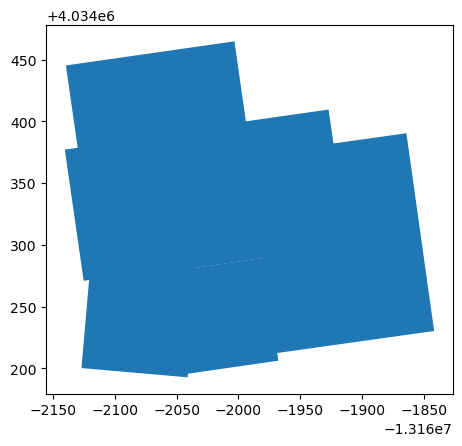

In [134]:
env1935Contig.plot()

# Main work

In [26]:
TREE_GEN_FILE_PATH = "C://Users//alek-//Documents//Wageningen Thesis//Study_Area_data//treesFromDeepLearningProcessedv2.shp"
treeGenPnts = gpd.read_file(TREE_GEN_FILE_PATH) #EPSG 3857 -> be mindful of CRS -> 

In [54]:
TREE_GEN_POLY_FILE_PATH = "C://Users//alek-//Documents//Wageningen Thesis//Study_Area_data//treesFromDeepLearningPolyFiltered.shp"
treeGenPoly =  gpd.read_file(TREE_GEN_POLY_FILE_PATH)

### Getting a tree centroid file

In [55]:
treeNewPnts = treeGenPnts.copy()
for treePnt in treeGenPnts.itertuples():
    if treeGenPoly.loc[treeGenPoly['fid'] == treePnt.fid].empty:
        treeNewPnts.drop(treeNewPnts.loc[treeNewPnts['fid'] == treePnt.fid].index, inplace=True)
    # for treePoly in treeGenPoly.itertuples():

In [84]:
treeblah.columns

Index(['fid', 'Class_x', 'Confidence_x', 'Shape_Leng_x', 'Shape_Area_x',
       'geometry_x', 'Class_y', 'Confidence_y', 'Shape_Leng_y', 'Shape_Area_y',
       'totheight', 'diameter', 'trunk', 'ttype'],
      dtype='object')

### Condensing all tree data
Combining tree point file with tree poly generated from ArcGIS deep learning toolbox

In [105]:
treePntsData = pd.DataFrame(treeGenPnts)
treePntsData.drop(columns='geometry')
treeblah = treeGenPoly.merge(treePntsData, on='fid').set_geometry("geometry_x").drop(columns='geometry_y')


treeNewPoly = gpd.GeoDataFrame({"totheight": [2.0],
                                "diameter": [1.0],
                                "trunk": [1.0],
                                "ttype":[1],
                                "tree": treeGenPoly.iloc[0]
                                })
def writeNewTree(treePnt, treePoly, treeGDFPoly):
    treeInfo = pd.DataFrame({
            "fid": treePoly.fid,
            "Class": treePoly.Class,
            "Confidence": treePoly.Confidence,
            "Shape_Leng": treePoly.Shape_Leng,
            "Shape_Area": treePoly.Shape_Area,
            "totheight": treePnt.totheight,
            "diameter": treePnt.diameter,
            "trunk": treePnt.trunk,
            "ttype": treePnt.ttype
        })
    treeGDF = gpd.GeoDataFrame(treeInfo, geometry=treePoly.geometry)
    if treeGDFPoly.empty:
        treeGDFPoly = treeGDF.copy()
    else:
        treeGDFPoly.concat




In [ ]:
# Converting tree type to what is necessary for land use fraction generation
treeblah["ttype"]=treeblah["ttype"]+2

In [108]:
treeblah.info

<bound method DataFrame.info of           fid Class_x  Confidence_x  Shape_Leng_x  Shape_Area_x  \
0         1.0    Tree     35.664061     12.250708     10.279565   
1         2.0    Tree     35.232085     16.153539     14.479387   
2         3.0    Tree     32.079437     14.670757      8.939622   
3         4.0    Tree     31.071532     23.030295     31.258678   
4         5.0    Tree     20.136076      6.876802      3.179865   
...       ...     ...           ...           ...           ...   
3085  10884.0    Tree     18.872863      7.793910      3.279861   
3086  10893.0    Tree     15.848495     14.573700     14.259472   
3087  10899.0    Tree     18.673836     19.139232     21.219102   
3088  10900.0    Tree     16.637890     17.430490     17.699251   
3089  10905.0    Tree     45.818320     24.513182     28.918777   

                                             geometry_x Class_y  Confidence_y  \
0     POLYGON ((-118.25262 34.04985, -118.25262 34.0...    Tree     35.664061   
1

Defining base map for study area based on how wide and high (420) it is

In [6]:
lon_min,lat_min,lon_max,lat_max = extentSHP.total_bounds
xlim = ([lon_min,lon_max])
ylim = ([lat_min,lat_max])

pnt1_lat_long = (lat_min, lon_min)
pnt2_lat_long = (lat_min, lon_max)
pnt3_lat_long = (lat_max, lon_min)
pnt4_lat_long = (lat_max, lon_max)

lon_dist = distance.geodesic(pnt1_lat_long, pnt2_lat_long).m
lat_dist = distance.geodesic(pnt1_lat_long, pnt3_lat_long).m

ncols = int(np.ceil(lon_dist)*2)
nrows = int(np.ceil(lat_dist)*2)
# base_data = np.ones((nrows,ncols), dtype=int)


In [14]:
extentSHP.total_bounds

array([-118.26352287,   34.02199683, -118.21261292,   34.05655503])

In [7]:
extentSHP.total_bounds

array([-118.25227863,   34.03201072, -118.22026357,   34.0499504 ])

Defining resolution of basemap based on trying to make smallest resolution 1x1 meters square

In [7]:

xres = (lon_max-lon_min)/float(ncols)
yres = (lat_max-lat_min)/float(nrows)
geotransform=(lon_min,xres,0,lat_max,0, -yres) 

In [8]:
driver = gdal.GetDriverByName("GTiff")
driver.Register()

2

Creating land cover raster that will eventually be written out with the land cover fractions

In [9]:
landCover_raster = driver.Create(OUT_PATH+"landCoverOutRedo.tif",ncols, nrows, 1 ,gdal.GDT_Float32)  # Open the file
landCover_raster.SetGeoTransform(geotransform)  # Specify its coordinates
srs = osr.SpatialReference()                 # Establish its coordinate encoding
srs.ImportFromEPSG(4326)                     # This one specifies WGS84 lat long.
                                             # Anyone know how to specify the 
                                             # IAU2000:49900 Mars encoding?
landCover_raster.SetProjection( srs.ExportToWkt() )   # Exports the coordinate system 
                                                   # to the file
landCover_raster.GetRasterBand(1).WriteArray(base_data)   # Writes my array to the raster

# landCover_raster.FlushCache()

0

In [31]:
landCover_raster.FlushCache()

landCover_raster = None

Reading all the rasterized versions of OSM, NDVI, and tree generation data

In [25]:
RASTER_PATH = "C://Users//alek-//Documents//Wageningen Thesis//Study_Area_data//ProcessedData//"
riverRasterPath = RASTER_PATH+"riverRasterizedReproj.tif"
buildingRasterPath = RASTER_PATH+"osmBuilding.tif"
# pitchesConcretePath = RASTER_PATH+"rasterizedPitchesConcreteReproj.tif"
# pitchesGrassPath = RASTER_PATH+"rasterizedPitchesGrassReproj.tif"
highwayRasterPath = RASTER_PATH+"osmHighwayPoly.tif"
leisureRasterPath = RASTER_PATH+"osmLeisure.tif"
treeRasterPath = RASTER_PATH+"rasterizedTreeDataReproj.tif"
NDVI_Green_RasterPath = RASTER_PATH+"NDVI_NAIP_merge_Green_band.tif"
NDVI_Red_RasterPath = RASTER_PATH+"NDVI_NAIP_merge_Red_band.tif"
base_dataPath = OUT_PATH+"landCoverOutRedo.tif"

In [ ]:
RasterPathLists = [riverRasterPath, buildingRasterPath, highwayRasterPath, leisureRasterPath, treeRasterPath, NDVI_Green_RasterPath, NDVI_Red_RasterPath, base_dataPath]#, NDVI_Top_RasterPath, NDVI_Bottom_RasterPath]
target_raster_list = [x.replace('.tif', '_alignedRedo.tif') for x in RasterPathLists]

In [33]:
base_dataAlignedPath = OUT_PATH+"landCoverOutRedo_alignedRedo.tif"

In [29]:
raster_info = pygeo.get_raster_info(buildingRasterPath)
raster_info

{'file_list': ['C://Users//alek-//Documents//Wageningen Thesis//Study_Area_data//ProcessedData//osmBuilding.tif'],
 'projection_wkt': 'GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]',
 'geotransform': (-118.2531245427427,
  4.285485410422728e-06,
  0.0,
  34.05065614274271,
  0.0,
  -4.285485410422728e-06),
 'pixel_size': (4.285485410422728e-06, -4.285485410422728e-06),
 'raster_size': (7800, 4716),
 'n_bands': 1,
 'nodata': [0.0],
 'overviews': [],
 'block_size': [7800, 1],
 'bounding_box': [np.float64(-118.2531245427427),
  np.float64(34.03044579354716),
  np.float64(-118.2196977565414),
  np.float64(34.05065614274271)],
 'datatype': 6,
 'numpy_type': numpy.float32}

Aligning all the rasters using bilinear sampling

In [32]:
pygeo.align_and_resize_raster_stack(

   base_raster_path_list=RasterPathLists,

   target_raster_path_list=target_raster_list,

   resample_method_list=['bilinear', 'bilinear','bilinear', 'bilinear','bilinear', 'bilinear','bilinear', 'bilinear'],

   target_pixel_size=raster_info['pixel_size'],

   bounding_box_mode='union',

   target_projection_wkt=raster_info['projection_wkt'])

In [34]:
#Open Rasters
riverRasterAligned = gdal.Open(RASTER_PATH+"riverRasterizedReproj_alignedRedo.tif")
buildingRasterAligned = gdal.Open(RASTER_PATH+"osmBuilding_alignedRedo.tif")
leisureRasterAligned = gdal.Open(RASTER_PATH+"osmLeisure_alignedRedo.tif")
highwayPolyRasterAligned = gdal.Open(RASTER_PATH+"osmHighwayPoly_alignedRedo.tif")
treeRasterAligned = gdal.Open(RASTER_PATH+"rasterizedTreeDataReproj_alignedRedo.tif")
base_dataAligned = gdal.Open(base_dataAlignedPath)
NDVI_Green_Raster_Aligned = gdal.Open(RASTER_PATH+"NDVI_NAIP_merge_Green_band_alignedRedo.tif")
NDVI_Red_Raster_Aligned = gdal.Open(RASTER_PATH+"NDVI_NAIP_merge_Red_band_alignedRedo.tif")

In [35]:
raster_info_aligned = pygeo.get_raster_info(RASTER_PATH+"riverRasterizedReproj_alignedRedo.tif")
raster_info_aligned

{'file_list': ['C://Users//alek-//Documents//Wageningen Thesis//Study_Area_data//ProcessedData//riverRasterizedReproj_alignedRedo.tif'],
 'projection_wkt': 'GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]',
 'geotransform': (-118.27929214578822,
  4.285485410422728e-06,
  0.0,
  34.15041317795027,
  0.0,
  -4.285485410422728e-06),
 'pixel_size': (4.285485410422728e-06, -4.285485410422728e-06),
 'raster_size': (25848, 59465),
 'n_bands': 1,
 'nodata': [0.0],
 'overviews': [],
 'block_size': [256, 256],
 'bounding_box': [np.float64(-118.27929214578822),
  np.float64(33.89557678801948),
  np.float64(-118.16852091889962),
  np.float64(34.15041317795027)],
 'datatype': 2,
 'numpy_type': numpy.uint16}

In [36]:
BandRiver = riverRasterAligned.GetRasterBand(1)
BandBuilding = buildingRasterAligned.GetRasterBand(1)
BandLeisure = leisureRasterAligned.GetRasterBand(1)
BandHighway = highwayPolyRasterAligned.GetRasterBand(1)
BandTrees = treeRasterAligned.GetRasterBand(1)
BandNDVIGreen = NDVI_Green_Raster_Aligned.GetRasterBand(1)
BandNDVIRed = NDVI_Red_Raster_Aligned.GetRasterBand(1)
BandBase = base_dataAligned.GetRasterBand(1)


# NDVI_Top_Raster = gdal.Open(RASTER_PATH+"NDVI_NAIP_TopReproj.tif")
# NDVI_Bottom_Raster = gdal.Open(RASTER_PATH+"NDVI_NAIP_BottomReproj.tif")

In [37]:
base_data_array = BandBase.ReadAsArray()
# buildingArray = BandBuilding.ReadAsArray()

In [38]:
greenNDVIArray = BandNDVIGreen.ReadAsArray()
redNDVIArray = BandNDVIRed.ReadAsArray()

In [39]:
int(greenNDVIArray.max()) - int(redNDVIArray.max())

-5

In [41]:
# buildingArray.max() # Verify that there is actually something there
greenNDVIArray.max()

np.uint16(247)

In [ ]:
# setting the values for the different fields 
pavement = 1.0
grass = 5.0
decidTree = 4.0

In [ ]:
NoData = 0.0 #BandBase.GetNoDataValue()  
NoDataRiver = BandRiver.GetNoDataValue()  
NoDataBuilding = BandBuilding.GetNoDataValue() 
NoDataLeisure = BandLeisure.GetNoDataValue()  
NoDataHighway = BandHighway.GetNoDataValue()  
NoDataTrees = BandTrees.GetNoDataValue()  #

In [44]:
nBands = buildingRasterAligned.RasterCount      # how many bands, to help you loop
nRows  = buildingRasterAligned.RasterYSize      # how many rows
nCols  = buildingRasterAligned.RasterXSize      # how many columns
dType  = BandBase.DataType          # the datatype for this band

In [ ]:
RowRange = range(nRows)
ColRange = range(nCols)
for ThisRow in RowRange:
    # read a single line from this band
    ThisLine = BandBase.ReadAsArray(0,ThisRow,nCols,1,nCols,1,dType)
    RiverLine = BandRiver.ReadAsArray(0,ThisRow,nCols,1,nCols,1,dType)
    BuildingLine = BandBuilding.ReadAsArray(0,ThisRow,nCols,1,nCols,1,dType)
    LeisureLine = BandLeisure.ReadAsArray(0,ThisRow,nCols,1,nCols,1,dType)
    HighwayLine = BandHighway.ReadAsArray(0,ThisRow,nCols,1,nCols,1,dType)
    TreesLine = BandTrees.ReadAsArray(0,ThisRow,nCols,1,nCols,1,dType)
    NDVIGreenLine = BandNDVIGreen.ReadAsArray(0,ThisRow,nCols,1,nCols,1,dType)
    NDVIRedLine = BandNDVIRed.ReadAsArray(0,ThisRow,nCols,1,nCols,1,dType)


    if ThisRow % 100 == 0: # report every 100 lines
        print ("Scanning %d of %d" % (ThisRow,nRows))

    for ThisCol in ColRange: # some simple test on the values
        ValRiver = RiverLine[0].item(ThisCol)
        ValBuilding = BuildingLine[0].item(ThisCol)
        ValLeisure = LeisureLine[0].item(ThisCol)
        ValHighway = HighwayLine[0].item(ThisCol)
        ValTrees = TreesLine[0].item(ThisCol)
        ValNDVIGreen = NDVIGreenLine[0].item(ThisCol)
        ValNDVIRed = NDVIRedLine[0].item(ThisCol)
        NDVIRedGreenDiff = int(ValNDVIRed) - int(ValNDVIGreen) 

        # If statement that determines what will appear in this raster cell based on priority
        # explained in detail in thesis report
        if (ValRiver != NoData):
            base_data_array[ThisRow,ThisCol] = round(ValRiver)
        elif (ValTrees != NoData):
            base_data_array[ThisRow,ThisCol] = round(ValTrees)
        elif(ValBuilding != NoData):
            base_data_array[ThisRow,ThisCol] = round(ValBuilding)
        elif(ValLeisure != NoData):
            base_data_array[ThisRow,ThisCol] = round(ValLeisure)
        elif(ValHighway != NoData):
            base_data_array[ThisRow,ThisCol] = round(ValHighway)
        elif((ValNDVIGreen > 150) and (ValNDVIRed < 250) and NDVIRedGreenDiff > int(30)):
            base_data_array[ThisRow,ThisCol] = round(grass)
        elif ((ValNDVIGreen > 180) and NDVIRedGreenDiff <= int(30)):
            base_data_array[ThisRow,ThisCol] = round(decidTree)
        else:
            base_data_array[ThisRow,ThisCol] = pavement

## Get output file
raster_info_aligned = pygeo.get_raster_info(RASTER_PATH+"osmBuilding_alignedRedo.tif")
geotransformOut = np.float64(raster_info_aligned['geotransform'])

landCoverOut_raster = driver.Create(OUT_PATH+"landCoverOutProcessedRedo_final3.tif",nCols, nRows, 1 ,gdal.GDT_Float32)  # Open the file
landCoverOut_raster.SetGeoTransform(geotransformOut)  # Specify its coordinates
srs = osr.SpatialReference()                 # Establish its coordinate encoding
srs.ImportFromEPSG(4326)                     # This one specifies WGS84 lat long.
                                             # Anyone know how to specify the 
                                             # IAU2000:49900 Mars encoding?
landCoverOut_raster.SetProjection( srs.ExportToWkt() )   # Exports the coordinate system 
                                                   # to the file
landCoverOut_raster.GetRasterBand(1).WriteArray(base_data_array)   # Writes my array to the raster

landCoverOut_raster.FlushCache()

landCoverOut_raster = None


Scanning 0 of 59465
Scanning 100 of 59465
Scanning 200 of 59465
Scanning 300 of 59465
Scanning 400 of 59465
Scanning 500 of 59465
Scanning 600 of 59465
Scanning 700 of 59465
Scanning 800 of 59465
Scanning 900 of 59465
Scanning 1000 of 59465
Scanning 1100 of 59465
Scanning 1200 of 59465
Scanning 1300 of 59465
Scanning 1400 of 59465
Scanning 1500 of 59465
Scanning 1600 of 59465
Scanning 1700 of 59465
Scanning 1800 of 59465
Scanning 1900 of 59465
Scanning 2000 of 59465
Scanning 2100 of 59465
Scanning 2200 of 59465
Scanning 2300 of 59465
Scanning 2400 of 59465
Scanning 2500 of 59465
Scanning 2600 of 59465
Scanning 2700 of 59465
Scanning 2800 of 59465
Scanning 2900 of 59465
Scanning 3000 of 59465
Scanning 3100 of 59465
Scanning 3200 of 59465
Scanning 3300 of 59465
Scanning 3400 of 59465
Scanning 3500 of 59465
Scanning 3600 of 59465
Scanning 3700 of 59465
Scanning 3800 of 59465
Scanning 3900 of 59465
Scanning 4000 of 59465
Scanning 4100 of 59465
Scanning 4200 of 59465
Scanning 4300 of 59465


In [199]:
geotransform

(np.float64(-118.25227862657917),
 np.float64(5.413435813227437e-06),
 0,
 np.float64(34.04995040372045),
 0,
 np.float64(-4.507459385839022e-06))

In [205]:
geotransformOut

array([-1.18279292e+02,  4.28548541e-06,  0.00000000e+00,  3.41504132e+01,
        0.00000000e+00, -4.28548541e-06])

In [ ]:
raster_info_aligned = pygeo.get_raster_info(RASTER_PATH+"osmBuilding_alignedRedo.tif")
geotransformOut = np.float64(raster_info_aligned['geotransform'])

In [218]:
base_data_array[0,0]

np.float32(1.0)

In [ ]:
landCoverOut_raster = driver.Create(OUT_PATH+"landCoverOutProcessedRedo_final3.tif",nCols, nRows, 1 ,gdal.GDT_Float32)  # Open the file
landCoverOut_raster.SetGeoTransform(geotransformOut)  # Specify its coordinates
srs = osr.SpatialReference()                 # Establish its coordinate encoding
srs.ImportFromEPSG(4326)                     # This one specifies WGS84 lat long.
                                             # Anyone know how to specify the 
                                             # IAU2000:49900 Mars encoding?
landCoverOut_raster.SetProjection( srs.ExportToWkt() )   # Exports the coordinate system 
                                                   # to the file
landCoverOut_raster.GetRasterBand(1).WriteArray(base_data_array)   # Writes my array to the raster

landCoverOut_raster.FlushCache()

landCoverOut_raster = None

In [ ]:
#Reproject
# riverRasterReproj = RASTER_PATH+"riverRasterizedReproj.tif"
# buildingRasterReproj = RASTER_PATH+"rasterizedOSMBuildingReproj.tif"
# pitchesConcreteReproj = RASTER_PATH+"rasterizedPitchesConcreteReproj.tif"
# pitchesGrassReproj = RASTER_PATH+"rasterizedPitchesGrassReproj.tif"
# treeRasterReproj = RASTER_PATH+"rasterizedTreeDataReproj.tif"
# NDVI_Top_RasterReproj = RASTER_PATH+"NDVI_NAIP_TopReproj.tif"
# NDVI_Bottom_RasterReproj = RASTER_PATH+"NDVI_NAIP_BottomReproj.tif"

Using the bounds defines by this extent find a distance in meters between all the corners, define a raster of 0.5 by 0.5 meters, all ones. Once this has been defined, define the CRS as 4326. Once that CRS has been defined, and all the other relevant information has been defined, we can start with sampling each vector layer one by one until the desired .tif file has been properly determined.

In [10]:


# extent = [-13163667.7263999991118908,4033287.4648000001907349, -13160301.7263999991118908,4035338.4648000001907349]

tags = {'building': True, 'highway': True, 'leisure':True, 'natural':True, 'public_transport':True, 
                'railway':True, 'waterway':True}
tagsLU = {'barrier': True, 'boundary': True, 'geological':True, 'landuse':True, 'man_made':True}



Grabbing OSM data based on bounding box of study area

In [11]:
osmData = ox.features.features_from_bbox(extentSHP.total_bounds, tags)    


In [12]:
osmLandUse = ox.features.features_from_bbox(extentSHP.total_bounds, tagsLU)

In [ ]:
osmLandUse

In [15]:
osmBuildingsNew = ox.features.features_from_bbox(extentSHP.total_bounds, {'building': True}) 

In [13]:
osmBuildings = ox.features.features_from_bbox(extentSHP.total_bounds, {'building': True}) 
osmHighway = ox.features.features_from_bbox(extentSHP.total_bounds, {'highway': True}) 
osmLeisure = ox.features.features_from_bbox(extentSHP.total_bounds, {'leisure': True}) 
osmNatural = ox.features.features_from_bbox(extentSHP.total_bounds, {'natural': True}) 
osmPublicTransit = ox.features.features_from_bbox(extentSHP.total_bounds, {'public_transport': True}) 
osmRailway = ox.features.features_from_bbox(extentSHP.total_bounds, {'railway': True}) 
osmWaterway = ox.features.features_from_bbox(extentSHP.total_bounds, {'waterway': True}) 

In [14]:
osmBarriers = ox.features.features_from_bbox(extentSHP.total_bounds, {'barrier': True}) 
# osmBoundaries = ox.features.features_from_bbox(extentSHP.total_bounds, {'boundary': True}) Non Existent in this area -> make this a try catch 
# osmGeological = ox.features.features_from_bbox(extentSHP.total_bounds, {'geological':True}) 
osmLandUseProper = ox.features.features_from_bbox(extentSHP.total_bounds, {'landuse':True}) 
osmManMade = ox.features.features_from_bbox(extentSHP.total_bounds, {'man_made':True}) 


In [ ]:
# x_dist = distance.geodesic(pnt1_lat_long, pnt2_lat_long).m
# y_dist = distance.geodesic(pnt1_lat_long, pnt3_lat_long).m

In [ ]:
# x_num = np.ceil(x_dist)*2
# y_num = np.ceil(y_dist)*2
# base_data = np.ones((int(y_num),int(x_num)), dtype=int) #Make it a base of ones which is associated with pavement -> however can also scale based on the input of the user to define what the most common land cover type is

In [ ]:
fig, ax = plt.subplots()
ax.set_xlim(xlim)
ax.set_ylim(ylim)

(34.03201071536481, 34.04995040372045)

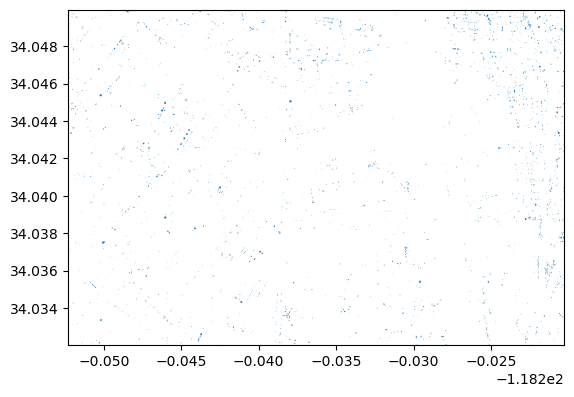

In [85]:
ax = treeblah.plot()
ax.set_xlim(xlim)
ax.set_ylim(ylim)

(34.03201071536481, 34.04995040372045)

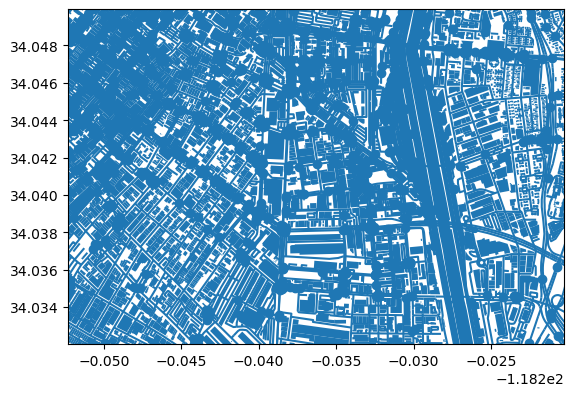

In [13]:
ax = osmData.plot()
ax.set_xlim(xlim)
ax.set_ylim(ylim)

(34.03201071536481, 34.04995040372045)

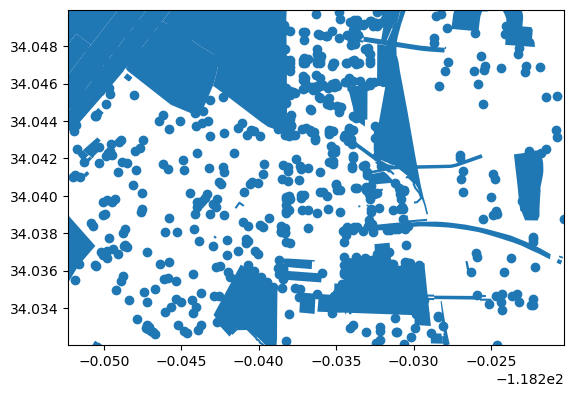

In [14]:
ax = osmLandUse.plot()
ax.set_xlim(xlim)
ax.set_ylim(ylim)

In [ ]:
print("Buildings:")
print(osmBuildings.head())
print("\nHighways:")
print(osmHighway.head())
print("\nLeisure:")
print(osmLeisure.head())
print("\nNatural:")
print(osmNatural.head())
print("\nPublic Transit:")
print(osmPublicTransit.head())
print("\nRailways:")
print(osmRailway.head())
print("\nWaterways:")
print(osmWaterway.head())


In [ ]:
pd.set_option('display.max_columns',None)
osmLeisure

(34.03201071536481, 34.04995040372045)

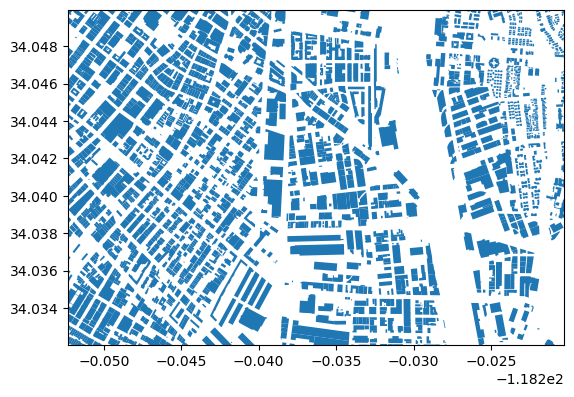

In [15]:
ax = osmBuildings.plot()
ax.set_xlim(xlim)
ax.set_ylim(ylim)

In [ ]:
display(osmHighway)


(34.03201071536481, 34.04995040372045)

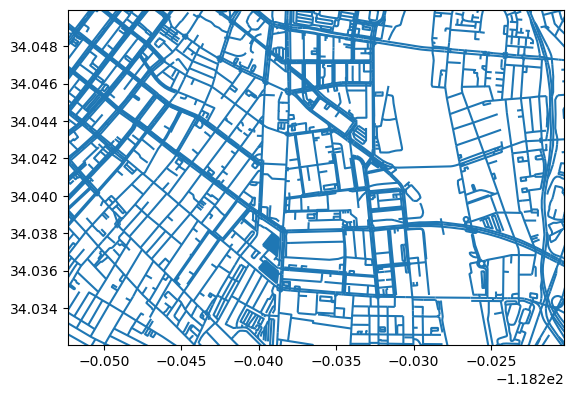

In [22]:
osmHighwayLine = osmHighway.loc[osmHighway.geometry.geometry.type=='LineString']
ax = osmHighwayLine.plot()
ax.set_xlim(xlim)
ax.set_ylim(ylim)

In [ ]:
osmNatural

In [24]:
osmTree = osmNatural.loc[osmNatural.natural=="tree"]

Removing geometries that could cause issues in exporting the data

In [23]:
osmLeisureProcessed = osmLeisure.loc[osmLeisure.geometry.geometry.type!='Point']
osmHighwayPolyProcessed = osmHighway.loc[osmHighway.geometry.geometry.type=='Polygon']
osmNaturalProcessed = osmNatural.loc[osmNatural.geometry.geometry.type!='Point']
osmPublicTransitProcessed = osmPublicTransit.loc[osmPublicTransit.geometry.geometry.type!='Point']
osmWaterwayProcessed = osmWaterway.loc[osmWaterway.geometry.geometry.type!='Point']

In [17]:
osmBuildingsProcessed = osmBuildingsNew.loc[osmBuildingsNew.geometry.geometry.type!='Point']
osmBuildingsProcessed.to_file(f"{OUT_PATH}OSMBuildingsPolyV3.shp", driver='ESRI Shapefile')


C:\Users\alek-\AppData\Local\Temp\ipykernel_32500\2945492695.py:2: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  osmBuildingsProcessed.to_file(f"{OUT_PATH}OSMBuildingsPolyV3.shp", driver='ESRI Shapefile')
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'addr:state' to 'addr_state'
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'gnis:feature_id' to 'gnis_featu'
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'addr:city' to 'addr_city'
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'addr:housenumber' to 'addr_house'
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packa

In [24]:
osmBuildings.to_file(f"{OUT_PATH}OSMBuildingsPolyNew.shp", driver='ESRI Shapefile')
osmLeisureProcessed.to_file(f"{OUT_PATH}OSMLeisurePolyNew.shp", driver='ESRI Shapefile') 
osmHighwayPolyProcessed.to_file(f"{OUT_PATH}OSMHighwayNewPoly.shp", driver='ESRI Shapefile') 
osmHighwayLine.to_file(f"{OUT_PATH}OSMHighwayNewLine.shp", driver='ESRI Shapefile') 
osmNaturalProcessed.to_file(f"{OUT_PATH}OSMNaturalPolyNew.shp", driver='ESRI Shapefile')
osmPublicTransitProcessed.to_file(f"{OUT_PATH}OSMPublicTransitPolyNew.shp", driver='ESRI Shapefile') 
osmWaterwayProcessed.to_file(f"{OUT_PATH}OSMWaterwayNewPoly.shp", driver='ESRI Shapefile') 


C:\Users\alek-\AppData\Local\Temp\ipykernel_43112\1799616014.py:1: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  osmBuildings.to_file(f"{OUT_PATH}OSMBuildingsPolyNew.shp", driver='ESRI Shapefile')
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'addr:city' to 'addr_city'
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'addr:housenumber' to 'addr_house'
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'addr:postcode' to 'addr_postc'
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'addr:state' to 'addr_state'
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogri

In [109]:
treeblah.to_file(f"{OUT_PATH}TreePoly.shp", driver='ESRI Shapefile') # Not super reliable when it comes to finding all the trees 

C:\Users\alek-\AppData\Local\Temp\ipykernel_33892\1052548694.py:1: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  treeblah.to_file(f"{OUT_PATH}TreePoly.shp", driver='ESRI Shapefile') # Not super reliable when it comes to finding all the trees
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'Confidence_x' to 'Confidence'
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'Shape_Leng_x' to 'Shape_Leng'
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'Shape_Area_x' to 'Shape_Area'
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Normalized/laundered field name: 'Confidence_y' to 'Confiden_1'
  ogr_write(
c:\Users\alek-\ana

(34.03201071536481, 34.04995040372045)

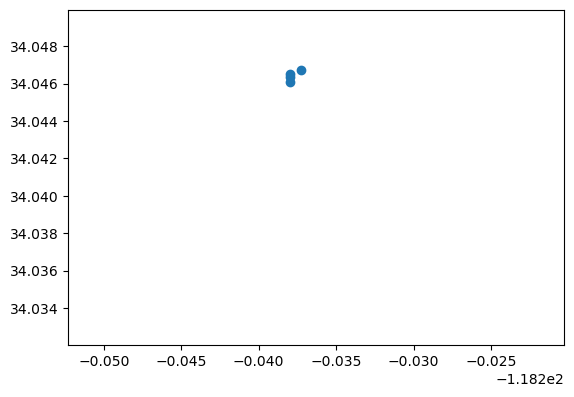

In [19]:
ax = osmTree.plot()
ax.set_xlim(xlim)
ax.set_ylim(ylim)

(34.03201071536481, 34.04995040372045)

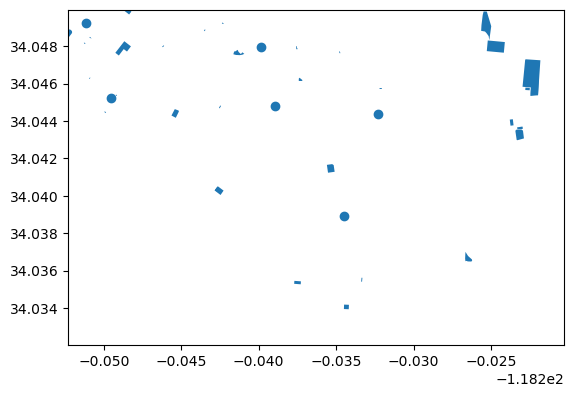

In [20]:
ax = osmLeisure.plot()
ax.set_xlim(xlim)
ax.set_ylim(ylim)

In [ ]:
display(osmHighwayLine)

In [ ]:
display(osmLeisure)

(34.03201071536481, 34.04995040372045)

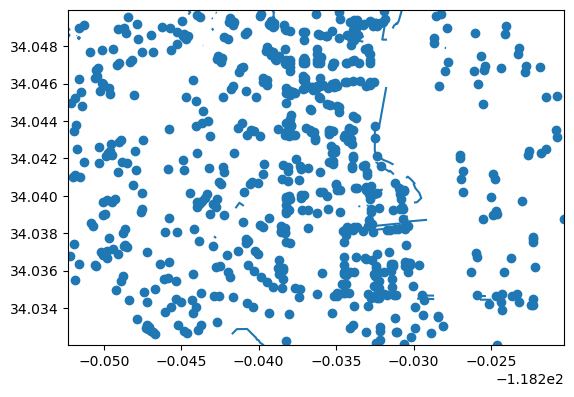

In [21]:
ax = osmBarriers.plot()
ax.set_xlim(xlim)
ax.set_ylim(ylim)

In [ ]:
display(osmBarriers)

Land Class Types:

1 - Paved

2 - Buildings

3 - Evergreen Trees

4 - Deciduous Trees

5 - Grass

6 - Bare Soil

7 - Water

8 - Grass Irrigated

9 - Concrete

Comments:
When trying to find a way to extract road networks, there's a plethora of trained deep learning models capable of doing this, however these models show a major limitation, namely prioritizing roads for vehicles, with very few (no found) models capable of extracting sidewalk footprints. The prioritization of self-driving vehicles is extremely problematic from the perspective of improving the quality of cities, and can be counter-productive.

Psuedo Code: 
Ask base type of land setting - e.g. 1 - 

Should rasterize the vector files within the bounds of the raster then go for each cell and figure out which is highest priority then write this out

# Scripts for processing UMEP output

Next big step is to normalize output from 500m grid and find the areas that are the worst/best

In [7]:
VECTOR_GRID_500M_PATH_W_OUTPUTS = "C://Users//alek-//Documents//Wageningen Thesis//Study_Area_data//SUEWPrepare//500m_grid_w_output.shp"
vectGrid500mOutputs =  gpd.read_file(VECTOR_GRID_500M_PATH_W_OUTPUTS)

In [ ]:
vectGrid500mOutputs

Normalize SUEWS outputs of interest across all grid cells

In [ ]:
# vectGrid500mNormalized = vectGrid500mOutputs.copy()

def NormalizeVectorGrid(vGrid):
    vectorGrid = vGrid.copy()

    surfaceMoistDeficitArr = vectorGrid['SMD'].copy()
    drainageArr = vectorGrid['Drainage'].copy()
    totMoistureChangeArr = vectorGrid['TotCh'].copy()
    RunOffArr = vectorGrid['RO'].copy()
    evapArr = vectorGrid['Evap'].copy()
    netStorageFluxArr = vectorGrid['QS'].copy()
    latentHeatFluxArr = vectorGrid['QE'].copy()
    sensibleHeatFluxArr = vectorGrid['QH'].copy()
    bulkSurfaceFluxArr = vectorGrid['Tsurf'].copy()

    surfaceMoistDeficitArr = (surfaceMoistDeficitArr-min(surfaceMoistDeficitArr))/(max(surfaceMoistDeficitArr)-min(surfaceMoistDeficitArr))
    drainageArr = (drainageArr-min(drainageArr))/(max(drainageArr) - min(drainageArr))
    totMoistureChangeArr = (totMoistureChangeArr-min(totMoistureChangeArr))/(max(totMoistureChangeArr)-min(totMoistureChangeArr))
    RunOffArr = (RunOffArr-min(RunOffArr))/(max(RunOffArr)-min(RunOffArr))
    evapArr = (evapArr-min(evapArr))/(max(evapArr)-min(evapArr))
    netStorageFluxArr = (netStorageFluxArr-min(netStorageFluxArr))/(max(netStorageFluxArr)-min(netStorageFluxArr))
    latentHeatFluxArr = (latentHeatFluxArr-min(latentHeatFluxArr))/(max(latentHeatFluxArr)-min(latentHeatFluxArr))
    sensibleHeatFluxArr = (sensibleHeatFluxArr-min(sensibleHeatFluxArr))/(max(sensibleHeatFluxArr)-min(sensibleHeatFluxArr))
    bulkSurfaceFluxArr = (bulkSurfaceFluxArr-min(bulkSurfaceFluxArr))/(max(bulkSurfaceFluxArr)-min(bulkSurfaceFluxArr))

    vectorGrid['SMD'] = surfaceMoistDeficitArr
    vectorGrid['Drainage'] = drainageArr
    vectorGrid['TotCh'] = totMoistureChangeArr
    vectorGrid['RO'] = RunOffArr
    vectorGrid['Evap'] = evapArr
    vectorGrid['QS'] = netStorageFluxArr
    vectorGrid['QE'] = latentHeatFluxArr
    vectorGrid['QH'] = sensibleHeatFluxArr
    vectorGrid['Tsurf'] = bulkSurfaceFluxArr

    return vectorGrid

# #Drainage	TotCh	RO	Evap	QS	QH	Tsurf
# for treePnt in treeGenPnts.itertuples():
#     if treeGenPoly.loc[treeGenPoly['fid'] == treePnt.fid].empty:
#         treeNewPnts.drop(treeNewPnts.loc[treeNewPnts['fid'] == treePnt.fid].index, inplace=True)
    # for treePoly in treeGenPoly.itertuples():

In [10]:
bleh = vectGrid500mOutputs['TotCh'].copy()
bleh = (bleh-min(bleh))/(max(bleh)-min(bleh))
max(bleh)

1.0

In [11]:
blehM = bleh * -1 + 1

In [12]:
vectGrid500mNormalized = NormalizeVectorGrid(vectGrid500mOutputs)


Originally it was intended to find the best and worst cells then increase resolution but this was later scrapped. However here is a function for finding the best cell - this method for scoring is still used though in the main jupyter notebook

In [26]:
def findBestCell(vectGridNorm, num=1, best=True, worst=True):
    surfaceMoistDeficitArr = vectGridNorm['SMD'].copy() #lower Better
    surfaceMoistDeficitArr = surfaceMoistDeficitArr * -1 + 1
    drainageArr = vectGridNorm['Drainage'].copy() # lower better
    drainageArr = drainageArr * -1 + 1
    totMoistureChangeArr = vectGridNorm['TotCh'].copy() # higher better
    RunOffArr = vectGridNorm['RO'].copy() # lower better
    RunOffArr = RunOffArr * -1 + 1
    evapArr = vectGridNorm['Evap'].copy() # lower better
    evapArr = evapArr * -1 + 1
    netStorageFluxArr = vectGridNorm['QS'].copy() # lower better
    netStorageFluxArr = netStorageFluxArr * -1 + 1
    sensibleHeatFluxArr = vectGridNorm['QH'].copy() # lower better
    sensibleHeatFluxArr = sensibleHeatFluxArr * -1 + 1
    bulkSurfaceFluxArr = vectGridNorm['Tsurf'].copy() # lower better
    bulkSurfaceFluxArr = bulkSurfaceFluxArr * -1 + 1

    totalScore = surfaceMoistDeficitArr + drainageArr + totMoistureChangeArr + RunOffArr + evapArr + netStorageFluxArr + sensibleHeatFluxArr + bulkSurfaceFluxArr
    if best and worst:
        best_worst = pd.Series([totalScore.nsmallest(num),totalScore.nlargest(num)])
    elif worst:
        # worstList = totalScore.nsmallest(num)
        best_worst = totalScore.nsmallest(num)
        # best_worst = [totalScore.apply(lambda x: x.nsmallest(num).index)]
    else:
        best_worst = totalScore.nlargest(num)


    return best_worst, totalScore

In [ ]:
vectGrid500mNormalized = NormalizeVectorGrid(vectGrid500mOutputs)
bestWorst500m, scores = findBestCell(vectGrid500mNormalized)

In [15]:
scores

0     2.538566
1     2.552261
2     2.526668
3     2.687511
4     2.505607
5     2.335958
6     2.669422
7     2.845114
8     2.603481
9     2.713355
10    3.001399
11    2.505468
12    2.697820
13    2.776889
14    2.714086
15    3.073320
16    2.881655
17    2.617254
18    2.928926
19    2.735693
20    3.712939
21    2.924796
22    2.700497
23    2.731493
24    2.661447
25    3.963224
26    4.492094
27    5.164842
28    4.523488
29    4.340039
30    5.183953
31    4.480127
32    4.298427
33    3.386251
34    4.008032
dtype: float64

The best and worst grid cells are cells 30, and 5 respectively, however cell 7 is also an area of interest due to its importance

In [16]:
aoI_vect = vectGrid500mNormalized.loc[vectGrid500mNormalized['id'] == 7.0].copy()
worst_vect = vectGrid500mNormalized.loc[vectGrid500mNormalized['id'] == 5.0].copy()
best_vect = vectGrid500mNormalized.loc[vectGrid500mNormalized['id'] == 30.0].copy()

In [17]:
aoI_vect.to_file(f"{OUT_PATH}500m_AoI_gridCell.shp", driver='ESRI Shapefile') 
worst_vect.to_file(f"{OUT_PATH}500m_worst_gridCell.shp", driver='ESRI Shapefile')
best_vect.to_file(f"{OUT_PATH}500m_best_gridCell.shp", driver='ESRI Shapefile')

c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Value -13163283.1991000008 of field left of feature 0 not successfully written. Possibly due to too larger number with respect to field width
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Value -13162783.1991000008 of field right of feature 0 not successfully written. Possibly due to too larger number with respect to field width
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Value -13163783.1991000008 of field left of feature 0 not successfully written. Possibly due to too larger number with respect to field width
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Value -13163283.1991000008 of field right of feature 0 not successfully written. Possibly due to too larger number with respect to field width
  ogr_write(
c:

In [6]:
VECTOR_GRID_100M_AOI_PATH_W_OUTPUTS = "C://Users//alek-//Documents//Wageningen Thesis//Study_Area_data//ProcessedData//100m_grid_AoI_w_outputs.shp"
vectGridAoI100mOutputs =  gpd.read_file(VECTOR_GRID_100M_AOI_PATH_W_OUTPUTS)

VECTOR_GRID_100M_BEST_PATH_W_OUTPUTS = "C://Users//alek-//Documents//Wageningen Thesis//Study_Area_data//ProcessedData//100m_grid_best_w_outputs.shp"
vectGridBest100mOutputs =  gpd.read_file(VECTOR_GRID_100M_BEST_PATH_W_OUTPUTS)

VECTOR_GRID_100M_WORST_PATH_W_OUTPUTS = "C://Users//alek-//Documents//Wageningen Thesis//Study_Area_data//ProcessedData//100m_grid_worst_w_outputs.shp"
vectGridWorst100mOutputs =  gpd.read_file(VECTOR_GRID_100M_WORST_PATH_W_OUTPUTS)

In [36]:
vectGrid100mAoINormalized = NormalizeVectorGrid(vectGridAoI100mOutputs)
worst100mAoI, scores = findBestCell(vectGrid100mAoINormalized, num=3, best=False)
vectGrid100mBestNormalized = NormalizeVectorGrid(vectGridBest100mOutputs)
best100mBest, scores = findBestCell(vectGrid100mBestNormalized, num=3, best=True, worst=False)
vectGrid100mWorstNormalized = NormalizeVectorGrid(vectGridWorst100mOutputs)
worst100mWorst, scores = findBestCell(vectGrid100mWorstNormalized, num=3, best=False)

In [31]:
worst100mAoI

13    1.995780
20    2.208452
0     2.270227
dtype: float64

In [37]:
best100mBest

3     4.982291
2     4.856511
18    4.459277
dtype: float64

In [38]:
worst100mWorst

9    1.671091
4    1.720331
0    1.726697
dtype: float64

In [49]:
worst100_aoI1_vect = vectGrid100mAoINormalized.loc[vectGrid100mAoINormalized['id'] == 14.0].copy()
worst100_aoI2_vect = vectGrid100mAoINormalized.loc[vectGrid100mAoINormalized['id'] == 21.0].copy()
worst100_aoI3_vect = vectGrid100mAoINormalized.loc[vectGrid100mAoINormalized['id'] == 1.0].copy()
best100_best1_vect = vectGrid100mBestNormalized.loc[vectGrid100mBestNormalized['id'] == 4.0].copy()
best100_best2_vect = vectGrid100mBestNormalized.loc[vectGrid100mBestNormalized['id'] == 3.0].copy()
best100_best3_vect = vectGrid100mBestNormalized.loc[vectGrid100mBestNormalized['id'] == 19.0].copy()
worst100_worst1_vect = vectGrid100mWorstNormalized.loc[vectGrid100mWorstNormalized['id'] == 10.0].copy()
worst100_worst2_vect = vectGrid100mWorstNormalized.loc[vectGrid100mWorstNormalized['id'] == 5.0].copy()
worst100_worst3_vect = vectGrid100mWorstNormalized.loc[vectGrid100mWorstNormalized['id'] == 1.0].copy()


In [45]:
OUT_PATH = "C://Users//alek-//Documents//Wageningen Thesis//Study_Area_data//ProcessedData//"

In [50]:
worst100_aoI1_vect.to_file(f"{OUT_PATH}100m_AoI_gridCellWorst1.shp", driver='ESRI Shapefile') 
worst100_aoI2_vect.to_file(f"{OUT_PATH}100m_AoI_gridCellWorst2.shp", driver='ESRI Shapefile')
worst100_aoI3_vect.to_file(f"{OUT_PATH}100m_AoI_gridCellWorst3.shp", driver='ESRI Shapefile')
best100_best1_vect.to_file(f"{OUT_PATH}100m_Best_gridCellWorst1.shp", driver='ESRI Shapefile') 
best100_best2_vect.to_file(f"{OUT_PATH}100m_Best_gridCellWorst2.shp", driver='ESRI Shapefile')
best100_best3_vect.to_file(f"{OUT_PATH}100m_Best_gridCellWorst3.shp", driver='ESRI Shapefile')
worst100_worst1_vect.to_file(f"{OUT_PATH}100m_Worst_gridCellWorst1.shp", driver='ESRI Shapefile') 
worst100_worst2_vect.to_file(f"{OUT_PATH}100m_Worst_gridCellWorst2.shp", driver='ESRI Shapefile')
worst100_worst3_vect.to_file(f"{OUT_PATH}100m_Worst_gridCellWorst3.shp", driver='ESRI Shapefile')

c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Value -13163083.1991000008 of field left of feature 0 not successfully written. Possibly due to too larger number with respect to field width
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Value -13162983.1991000008 of field right of feature 0 not successfully written. Possibly due to too larger number with respect to field width
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Value -13162883.1991000008 of field left of feature 0 not successfully written. Possibly due to too larger number with respect to field width
  ogr_write(
c:\Users\alek-\anaconda3\envs\thesisEnv\Lib\site-packages\pyogrio\raw.py:723: RuntimeWarning: Value -13162783.1991000008 of field right of feature 0 not successfully written. Possibly due to too larger number with respect to field width
  ogr_write(
c:

# Missing Data Recreation

In [ ]:
folder = "C://Users//alek-//Documents//Wageningen Thesis//software_exploration//data_for_spatial_sig//output//" 

used_characteristics_dict_v2 = {
    'sscCCo': 'circular compactness of ETC', #
    'sicCAR': 'covered area ratio of ETC', # building cover
    'lddNDe': 'local node density of street network',
    'sdsSPO': 'openness of street profile', #
    'ltbIBD': 'mean inter-building distance',
    'mtbAli': 'alignment of neighbouring buildings',
    'lieWCe': 'area-weighted ETCs of enclosure', # 
}
tess = gpd.read_parquet(folder + "tess.pq")
fullChunks = gpd.read_parquet(folder + "combTessChunks.pq")
tessWithClusters = gpd.read_parquet(folder + "finalSpatialClusteringEnvPredAll.pq")
# tessWithClusters.set_index(envPredTess.index, inplace=True)
pd.set_option('display.max_columns', None)
tessWithClusters.head(1)
envPredTess = gpd.read_parquet(folder + "envPredTess.pq")
# tessWithClusters = envPredTess.merge(tessWithClusters, on="geometry")
# envPredTess.head(1)
fullChunks.loc[fullChunks.ltbIBD==np.nan]
tessWithClusters.ltbIBD_q2
fullChunks["sicCAR"].replace(np.nan, 0, inplace=True)
fullChunksCorr1 = fullChunks.copy()
fullChunks["sicCAR"].replace(np.nan, 0, inplace=True)


interbuilding = fullChunks.ltbIBD
alignment = fullChunks.mtbAli 
fullChunks["ltbIBD"].loc[interbuilding.isnull()] = tessWithClusters["ltbIBD_q2"].loc[interbuilding.isnull()]
fullChunks["mtbAli"].loc[alignment.isnull()] = tessWithClusters["mtbAli_q2"].loc[alignment.isnull()]
fullChunks["ltbIBD"].replace(np.nan, 0, inplace=True)
fullChunks["mtbAli"].replace(np.nan, 0, inplace=True)

fullChunksCorr2 = fullChunks.copy()
# fullChunksCorr1 = fullChunksCorr1.merge(tessWithClusters[["geometry", "accessScore", "POP20", 
#                                                         "QH", "QE", "QS", "Tsurf", "Evap",
#                                                         "RO", "TotCh", "Drainage", "SMD", 
#                                                         "heat_score", "water_score"]], 
#                                                         on="geometry")
fullChunksCorr2 = fullChunksCorr2.merge(tessWithClusters[["geometry", "accessScore", "POP20", 
                                                        "QH", "QE", "QS", "Tsurf", "Evap",
                                                        "RO", "TotCh", "Drainage", "SMD", 
                                                        "heat_score", "water_score"]], 
                                                        on="geometry")
# fullChunksCorr1.set_index(fullChunks.index, inplace=True)
fullChunksCorr2.set_index(fullChunks.index, inplace=True)
# fullChunksCorr.head(1)

scores = ["accessScore", "heat_score", "water_score"]
# bv1 = Moran_Local_BV.by_col(df=fullChunksCorr1, x=usedChars, y=scores, w=wFullChunks1)    
# bv2 = Moran_Local_BV.by_col(df=fullChunksCorr2, x=usedChars, y=scores, w=wFullChunks2)    

# "access_score_"+ usedChars[0] + "_quadrant"


C:\Users\alek-\AppData\Local\Temp\ipykernel_46148\3555085512.py:23: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  fullChunks["sicCAR"].replace(np.nan, 0, inplace=True)
C:\Users\alek-\AppData\Local\Temp\ipykernel_46148\3555085512.py:25: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.



In [182]:
fullChunksCorr2.head(1)

,uID,eID,sdbAre,sdbPer,sdbCoA,ssbCCo,ssbCor,ssbSqu,ssbERI,ssbElo,ssbCCM,ssbCCD,stbOri,sdcLAL,sdcAre,sscCCo,sscERI,stcOri,sicCAR,stbCeA,building,bdShDv,mtbAli,mtbNDi,mtcWNe,mdcAre,ltcWRE,ltbIBD,ltcRea,ltcAre,nodeID,sdsSPW,sdsSWD,sdsSPO,sdsLen,sssLin,ldsMSL,mtdDeg,lcdMes,linP3W,linP4W,linPDE,lcnClo,ldsCDL,xcnSCl,mtdMDi,clsCnt,btwCnt,strCnt,lddNDe,linWID,edgeID_keys,edgeID_values,geometry,ldeAre,ldePer,lseCCo,lseERI,lseCWA,lteOri,lteWNB,lieWCe,edgeID_primary,stbSAl,sddAre,sdsAre,sisBpM,misCel,mdsAre,lisCel,ldsAre,accessScore,POP20,QH,QE,QS,Tsurf,Evap,RO,TotCh,Drainage,SMD,heat_score,water_score
tID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
73,3091.0,32,371.632256,113.530118,0.0,0.190672,6.0,23.946985,0.876081,0.225782,18.737334,8.406422,12.327992,264.207183,15515.536805,0.283001,0.689998,6.626343,0.023952,5.701648,warehouse,1.90261,10.419835,43.466765,0.010434,69906.218581,0.00011,48.459057,117,536671.474084,1958,34.615892,3.138558,0.776642,315.704687,0.762635,5591.066189,3,0.043478,0.746988,0.120482,0.084337,0.000014,615.833798,0.0,501.760287,0.000274,0.001357,0.735461,0.005451,0.01077,"[2474, 2750, 2805, 2806, 2808, 2553, 2751]","[3.2309866670151794e-05, 0.3569879421911007, 0...","POLYGON ((-13160343.549 4033974.556, -13160342...",81240.992723,2900.871079,0.141697,0.498043,955.879558,3.798012,0.006894,0.000332,2750.0,16.675389,28329.317397,48860.114957,0.015221,20.623744,200668.769972,26.239703,306777.163556,1.051722,50.418674,50.080499,12.224602,7.335546,21.113449,0.017667,0.024541,-0.006982,0.0299,79.503764,2.575741,0.719136


In [183]:

# [usedChars[2]] + scores
# bv2IvalCheck = bv2[usedChars + scores].corr(method="kendall")
# 'sscCCo': 'circular compactness of ETC', #
    # 'sicCAR': 'covered area ratio of ETC', # building cover
    # # 'lddNDe': 'local node density of street network',
    # 'sdsSPO': 'openness of street profile', #
    # 'ltbIBD': 'mean inter-building distance',
    # 'mtbAli': 'alignment of neighbouring buildings',
    # 'lieWCe': 'area-weighted ETCs of enclosure', #
bv2sscCCo = fullChunksCorr2[['sscCCo'] + scores].corr(method="kendall")
bv2sicCAR = fullChunksCorr2[['sicCAR'] + scores].corr(method="kendall")
bv2lddNDe = fullChunksCorr2[['lddNDe'] + scores].corr(method="kendall")
bv2sdsSPO = fullChunksCorr2[['sdsSPO'] + scores].corr(method="kendall")
bv2ltbIBD = fullChunksCorr2[['ltbIBD'] + scores].corr(method="kendall")
bv2mtbAli = fullChunksCorr2[['mtbAli'] + scores].corr(method="kendall")
bv2lieWCe = fullChunksCorr2[['lieWCe'] + scores].corr(method="kendall")

In [186]:
bv2sscCCo


,sscCCo,accessScore,heat_score,water_score
sscCCo,1.000000,0.029976,0.078894,-0.097466
accessScore,0.029976,1.000000,-0.155702,-0.111549
heat_score,0.078894,-0.155702,1.000000,0.274462
water_score,-0.097466,-0.111549,0.274462,1.000000


In [187]:
bv2sicCAR


,sicCAR,accessScore,heat_score,water_score
sicCAR,1.000000,0.037052,-0.054206,-0.313381
accessScore,0.037052,1.000000,-0.155702,-0.111549
heat_score,-0.054206,-0.155702,1.000000,0.274462
water_score,-0.313381,-0.111549,0.274462,1.000000


In [188]:
bv2lddNDe


,lddNDe,accessScore,heat_score,water_score
lddNDe,1.000000,0.030689,-0.138590,-0.128743
accessScore,0.030689,1.000000,-0.155702,-0.111549
heat_score,-0.138590,-0.155702,1.000000,0.274462
water_score,-0.128743,-0.111549,0.274462,1.000000


In [189]:
bv2sdsSPO


,sdsSPO,accessScore,heat_score,water_score
sdsSPO,1.000000,-0.022286,0.017456,0.249602
accessScore,-0.022286,1.000000,-0.155702,-0.111549
heat_score,0.017456,-0.155702,1.000000,0.274462
water_score,0.249602,-0.111549,0.274462,1.000000


In [190]:
bv2ltbIBD


,ltbIBD,accessScore,heat_score,water_score
ltbIBD,1.000000,0.049749,-0.053562,0.080147
accessScore,0.049749,1.000000,-0.155702,-0.111549
heat_score,-0.053562,-0.155702,1.000000,0.274462
water_score,0.080147,-0.111549,0.274462,1.000000


In [191]:
bv2mtbAli


,mtbAli,accessScore,heat_score,water_score
mtbAli,1.000000,0.013448,0.041248,0.045811
accessScore,0.013448,1.000000,-0.155702,-0.111549
heat_score,0.041248,-0.155702,1.000000,0.274462
water_score,0.045811,-0.111549,0.274462,1.000000


In [192]:
bv2lieWCe

,lieWCe,accessScore,heat_score,water_score
lieWCe,1.000000,-0.094516,0.079234,0.183274
accessScore,-0.094516,1.000000,-0.155702,-0.111549
heat_score,0.079234,-0.155702,1.000000,0.274462
water_score,0.183274,-0.111549,0.274462,1.000000


In [193]:
UMEP_ANALYSIS_folder = "C://Users//alek-//Documents//Wageningen Thesis//software_exploration//data_for_spatial_sig//UMEP//" 


In [194]:
groundTruth_gdf = gpd.read_file(UMEP_ANALYSIS_folder + "heat_severitiy_LA_2023.gpkg")

In [195]:
groundTruth = groundTruth_gdf[["gridcode","geometry"]].copy()
groundTruth["normSeverity"] = (groundTruth.gridcode - np.min(groundTruth.gridcode))/(np.max(groundTruth.gridcode)- np.min(groundTruth.gridcode))


In [196]:
envPredScoreGrid = gpd.read_parquet(folder + "envPredGridScored")
envHeatScoreGrid = envPredScoreGrid[["heat_score","geometry"]].copy()
normHeatScoreGrid = envHeatScoreGrid.copy()
normHeatScoreGrid.heat_score = (normHeatScoreGrid.heat_score - np.min(normHeatScoreGrid.heat_score))/(np.max(normHeatScoreGrid.heat_score) - np.min(normHeatScoreGrid.heat_score))

In [197]:
groundTruth = groundTruth.to_crs(envHeatScoreGrid.crs)

In [198]:
envHeatScoreGridv2 = normHeatScoreGrid.overlay(groundTruth, how="intersection")
envHeatScoreGridv2[["gridcode","heat_score"]].corr(method='kendall')

,gridcode,heat_score
gridcode,1.000000,-0.181645
heat_score,-0.181645,1.000000


In [199]:
install('tobler')


In [200]:
from tobler.area_weighted import area_interpolate


In [201]:
heat_score_checking = area_interpolate(normHeatScoreGrid, groundTruth, intensive_variables=["heat_score"], n_jobs=1)
envHeatScoreCheck = groundTruth[["normSeverity","gridcode","geometry"]].copy()
envHeatScoreCheck = envHeatScoreCheck.to_crs(envHeatScoreGrid.crs)
envHeatScoreCheck = heat_score_checking.merge(envHeatScoreCheck)
envHeatScoreCheck[["gridcode","heat_score"]].corr(method='kendall')

,gridcode,heat_score
gridcode,1.000000,-0.364113
heat_score,-0.364113,1.000000


In [207]:
install('dask')


In [212]:
upgrade('pyarrow')

In [208]:

import dask.dataframe as dd


In [219]:
combChunksEdges = gpd.read_parquet(folder + "combTessChunks.pq")

In [221]:
edge_13 = gpd.read_parquet(folder + "edges//edges_13.pq")

In [ ]:
combChunksEdges

,uID,eID,sdbAre,sdbPer,sdbCoA,ssbCCo,ssbCor,ssbSqu,ssbERI,ssbElo,ssbCCM,ssbCCD,stbOri,sdcLAL,sdcAre,sscCCo,sscERI,stcOri,sicCAR,stbCeA,building,bdShDv,mtbAli,mtbNDi,mtcWNe,mdcAre,ltcWRE,ltbIBD,ltcRea,ltcAre,nodeID,sdsSPW,sdsSWD,sdsSPO,sdsLen,sssLin,ldsMSL,mtdDeg,lcdMes,linP3W,linP4W,linPDE,lcnClo,ldsCDL,xcnSCl,mtdMDi,clsCnt,btwCnt,strCnt,lddNDe,linWID,edgeID_keys,edgeID_values,geometry,ldeAre,ldePer,lseCCo,lseERI,lseCWA,lteOri,lteWNB,lieWCe,edgeID_primary,stbSAl,sddAre,sdsAre,sisBpM,misCel,mdsAre,lisCel,ldsAre
tID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
73,3091.0,32,371.632256,113.530118,0.0,0.190672,6.0,23.946985,0.876081,0.225782,18.737334,8.406422,12.327992,264.207183,15515.536805,0.283001,0.689998,6.626343,0.023952,5.701648,warehouse,1.902610,10.419835,43.466765,0.010434,69906.218581,0.000110,48.459057,117,536671.474084,1958,34.615892,3.138558,0.776642,315.704687,0.762635,5591.066189,3,0.043478,0.746988,0.120482,0.084337,0.000014,615.833798,0.000000,501.760287,0.000274,0.001357,0.735461,0.005451,0.010770,"[2474, 2750, 2805, 2806, 2808, 2553, 2751]","[3.2309866670151794e-05, 0.3569879421911007, 0...","POLYGON ((-13160343.549 4033974.556, -13160342...",81240.992723,2900.871079,0.141697,0.498043,955.879558,3.798012,0.006894,0.000332,2750.0,16.675389,28329.317397,48860.114957,0.015221,20.623744,200668.769972,26.239703,306777.163556
74,2863.0,32,166.163780,57.770318,0.0,0.461782,10.0,0.131057,0.956091,0.472188,7.451297,2.648363,3.591856,124.593416,4049.351504,0.332128,0.804701,5.116313,0.041035,1.524457,residential,1.837083,16.354318,34.536763,0.018826,49541.543570,0.000099,48.828186,101,489784.287770,1958,27.481780,4.804368,0.668845,305.803721,0.813673,4149.187682,3,0.043478,0.746988,0.120482,0.084337,0.000014,615.833798,0.000000,501.760287,0.000274,0.001357,0.735461,0.005451,0.010770,"[2808, 3041, 3043, 3044, 2751]","[0.19009515025482024, 0.07170350210901814, 6.9...","POLYGON ((-13160324.689 4033973.323, -13160325...",81240.992723,2900.871079,0.141697,0.498043,955.879558,3.798012,0.006894,0.000332,2751.0,2.643613,28329.317397,52953.582665,0.026693,13.002968,194832.330891,23.469002,394108.393593
75,3006.0,32,68.670813,33.943324,0.0,0.520211,4.0,8.773791,0.999046,0.651467,6.046720,0.572362,30.838583,77.576117,1406.575211,0.297589,0.981358,37.883245,0.048821,7.044662,shed,1.843914,1.131588,1.494919,0.017443,40370.769150,0.000094,48.828186,97,477836.714617,2190,23.441886,5.491877,0.616605,347.729585,0.763677,3420.870050,3,0.200000,0.900000,0.000000,0.100000,0.000016,70.293560,0.142857,157.765093,0.000261,0.000842,0.710117,0.008235,0.014823,"[3044, 2751]","[0.692449609529219, 0.30755039047078103]","POLYGON ((-13160327.569 4034146.77, -13160327....",81240.992723,2900.871079,0.141697,0.498043,955.879558,3.798012,0.006894,0.000332,3044.0,12.796872,5325.372355,56206.726067,0.023603,12.460403,194917.363139,21.690605,404301.399601
76,3013.0,32,35.009607,23.805020,0.0,0.621888,4.0,0.022377,1.000021,0.805863,4.232332,0.000808,12.961117,32.714188,384.202868,0.457087,1.000194,10.317868,0.091123,2.643249,shed,1.865582,9.728452,14.202519,0.025336,9877.595466,0.000094,39.705910,42,265650.593530,2193,15.857142,6.268226,0.469697,331.445530,0.661399,1256.670791,3,0.189189,0.904762,0.000000,0.095238,0.000020,315.161787,0.200000,131.152794,0.000265,0.000421,0.733789,0.008445,0.015281,[3044],[1.0],"POLYGON ((-13160311.193 4034169.041, -13160311...",81240.992723,2900.871079,0.141697,0.498043,955.879558,3.798012,0.006894,0.000332,3044.0,5.080593,25624.949495,54367.852586,0.027154,10.000000,177436.243655,18.000000,401257.566551
77,2866.0,32,353.375422,114.954233,0.0,0.248786,12.0,0.261488,0.778380,0.296983,10.850555,7.433556,13.408967,82.897253,3209.533517,0.594664,1.015689,12.847385,0.110102,0.561582,residential,2.085026,6.762564,13.770921,0.013424,26036.241181,0.000093,41.215387,55,288305.199462,2210,31.988819,5.451616,0.666180,294.808360,0.797060,2521.428093,1,0.162162,0.857143,0.000000,0.095238,0.000010,244.868227,0.0

In [237]:
edgesMCA_disp = edge_13[["geometry"]].copy()

In [261]:
edgeCentrality = edgesMCA_disp.copy()
edgeCentrality["sumEdges"] = 0
edgeCentrality["closeCentrality"] = 0
edgeCentrality["betweenCentrality"] = 0
edgeCentrality["straightCentrality"] = 0
# edgeBetweenCentrality = edgesMCA_disp.copy()
# edgeStraightnessCentrality = edgesMCA_disp.copy()

inputs = iter(range(len(combChunksEdges)))

for i in inputs:
    edges = combChunksEdges["edgeID_keys"].iloc[i]
    edgeVals = combChunksEdges["edgeID_values"].iloc[i]

    edgeInputs = iter(range(len(edges)))
    for j in edgeInputs:
        edgeCentrality["closeCentrality"].iloc[edges[j]] += edgeVals[j]*combChunksEdges["clsCnt"].iloc[i]
        edgeCentrality["betweenCentrality"].iloc[edges[j]] += edgeVals[j]*combChunksEdges["btwCnt"].iloc[i]
        edgeCentrality["straightCentrality"].iloc[edges[j]] += edgeVals[j]*combChunksEdges["strCnt"].iloc[i]
        edgeCentrality["sumEdges"].iloc[edges[j]] += edgeVals[j]

C:\Users\alek-\AppData\Local\Temp\ipykernel_46148\1367704976.py:17: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  edgeCentrality["closeCentrality"].iloc[edges[j]] += edgeVals[j]*combChunksEdges["clsCnt"].iloc[i]
C:\Users\alek-\AppData\Local\

In [262]:
edgeCentrality["sumEdges"].loc[edgeCentrality["sumEdges"] == 0] = 1
edgeCentrality["closeCentrality"] = edgeCentrality["closeCentrality"]/edgeCentrality["sumEdges"]
edgeCentrality["betweenCentrality"] = edgeCentrality["betweenCentrality"]/edgeCentrality["sumEdges"]
edgeCentrality["straightCentrality"] = edgeCentrality["straightCentrality"]/edgeCentrality["sumEdges"]


C:\Users\alek-\AppData\Local\Temp\ipykernel_46148\2836101061.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  edgeCentrality["sumEdges"].loc[edgeCentrality["sumEdges"] == 0] = 1


In [268]:
edgeCentrality.drop(columns=["sumEdges"]).to_parquet(folder + "edgeMCA.pq")